# Статистичний аналіз результатів чемпіонату світу Формули-1 (1950–2025)

Курсова робота з дисципліни «Мови програмування для аналізу даних».
Виконав(ла): Юхно О. В., група 401-ТН.

**Джерело даних:** [F1DB – Open Source Formula 1 Database](https://github.com/f1db/f1db),
реліз `v2026.20.0` (9 листопада 2026), ліцензія CC BY 4.0.

**Мета:** дослідити, як змінювались конкурентність, надійність і результати гонок Формули-1
за 76 сезонів і від чого залежить результат пілота в гонці.

**Дослідницькі питання**
1. Як змінювалась конкурентність чемпіонату: скільки різних переможців у сезоні та наскільки домінувала найсильніша команда?
2. Наскільки стартова позиція визначає результат гонки і чи відрізняється це для вуличних трас?
3. Як змінились надійність машин і причини сходів з дистанції?
4. Хто з пілотів і команд найефективніший і як змінювались лідери по десятиліттях?
5. Чи змінився вік пілотів і чи є перевага домашньої гонки?
6. Як змінився час піт-стопів?

## 1. Підготовка середовища
Якщо даних немає в `data/raw`, функція `ensure_raw_data()` завантажує архів з релізу F1DB на GitHub.

In [1]:
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["axes.titleweight"] = "bold"

In [2]:
# ноутбук лежить у notebooks/, тому корінь проєкту на рівень вище;
# у Colab (без репозиторію) все створюється в поточній папці
ROOT = Path("..") if Path("../data").exists() else Path(".")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
EXPORTS = ROOT / "results" / "exports"
TABLEAU = ROOT / "tableau"
for folder in [RAW, PROCESSED, FIGURES, EXPORTS, TABLEAU]:
    folder.mkdir(parents=True, exist_ok=True)

F1DB_RELEASE = "v2026.20.0"
F1DB_URL = f"https://github.com/f1db/f1db/releases/download/{F1DB_RELEASE}/f1db-csv.zip"
TABLES = ["races-race-results", "races", "drivers", "constructors",
          "circuits", "countries", "grands-prix", "races-pit-stops"]


def ensure_raw_data():
    """Завантажує потрібні таблиці з релізу F1DB, якщо їх ще немає в data/raw."""
    missing = [t for t in TABLES if not (RAW / f"f1db-{t}.csv").exists()]
    if not missing:
        return "Усі таблиці вже є в data/raw"
    zip_path = RAW / "f1db-csv.zip"
    urllib.request.urlretrieve(F1DB_URL, zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        for t in missing:
            archive.extract(f"f1db-{t}.csv", RAW)
    zip_path.unlink()
    return f"Завантажено {len(missing)} таблиць з релізу {F1DB_RELEASE}"


def load(name, **kwargs):
    return pd.read_csv(RAW / f"f1db-{name}.csv", **kwargs)


def save_fig(fig, name):
    fig.savefig(FIGURES / name, dpi=200, bbox_inches="tight")


print(ensure_raw_data())

Усі таблиці вже є в data/raw


## 2. Завантаження та первинне дослідження даних
Використано 8 таблиць F1DB, зв'язаних ключами:
`results.raceId → races.id`, `results.driverId → drivers.id`, `results.constructorId → constructors.id`,
`races.circuitId → circuits.id`, `races.grandPrixId → grands_prix.id`, `drivers.nationalityCountryId` і `circuits.countryId → countries.id`,
`pit_stops.raceId → races.id`.

In [3]:
results = load("races-race-results", low_memory=False)
races = load("races", parse_dates=["date"])
drivers = load("drivers", parse_dates=["dateOfBirth"])
constructors = load("constructors")
circuits = load("circuits")
countries = load("countries")
grands_prix = load("grands-prix")
pit_stops = load("races-pit-stops")

tables = {"results": results, "races": races, "drivers": drivers,
          "constructors": constructors, "circuits": circuits,
          "countries": countries, "grands_prix": grands_prix,
          "pit_stops": pit_stops}
pd.DataFrame({name: {"рядків": t.shape[0], "стовпців": t.shape[1]}
              for name, t in tables.items()}).T

,рядків,стовпців
results,27731,34
races,1172,47
drivers,921,32
constructors,187,22
circuits,78,13
countries,249,7
grands_prix,54,7
pit_stops,22755,15


In [4]:
results = results[["raceId", "year", "round", "driverId", "constructorId",
                   "sharedCar", "positionNumber", "positionText", "laps",
                   "reasonRetired", "points", "polePosition",
                   "gridPositionNumber", "gridPositionText", "pitStops"]]
races = races[["id", "year", "round", "date", "grandPrixId", "circuitId",
               "circuitType", "laps", "distance"]]
drivers = drivers[["id", "name", "gender", "dateOfBirth", "nationalityCountryId"]]
constructors = constructors[["id", "name", "countryId"]]
circuits = circuits[["id", "name", "type", "placeName", "countryId",
                     "latitude", "longitude", "length", "turns"]]
countries = countries[["id", "name", "continentId"]]
grands_prix = grands_prix[["id", "name"]]
pit_stops = pit_stops[["raceId", "year", "driverId", "constructorId",
                       "stop", "lap", "timeMillis"]]
results.head()

,raceId,year,round,driverId,constructorId,sharedCar,positionNumber,positionText,laps,reasonRetired,points,polePosition,gridPositionNumber,gridPositionText,pitStops
0,1,1950,1,nino-farina,alfa-romeo,False,1.0,1,70.0,NaN,9.0,True,1.0,1,NaN
1,1,1950,1,luigi-fagioli,alfa-romeo,False,2.0,2,70.0,NaN,6.0,False,2.0,2,NaN
2,1,1950,1,reg-parnell,alfa-romeo,False,3.0,3,70.0,NaN,4.0,False,4.0,4,NaN
3,1,1950,1,yves-giraud-cabantous,talbot-lago,False,4.0,4,68.0,NaN,3.0,False,6.0,6,NaN
4,1,1950,1,louis-rosier,talbot-lago,False,5.0,5,68.0,NaN,2.0,False,9.0,9,NaN


In [5]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27731 entries, 0 to 27730
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   raceId              27731 non-null  int64  
 1   year                27731 non-null  int64  
 2   round               27731 non-null  int64  
 3   driverId            27731 non-null  object 
 4   constructorId       27731 non-null  object 
 5   sharedCar           27731 non-null  bool   
 6   positionNumber      16793 non-null  float64
 7   positionText        27731 non-null  object 
 8   laps                25799 non-null  float64
 9   reasonRetired       10136 non-null  object 
 10  points              8612 non-null   float64
 11  polePosition        27731 non-null  bool   
 12  gridPositionNumber  25714 non-null  float64
 13  gridPositionText    25958 non-null  object 
 14  pitStops            13236 non-null  float64
dtypes: bool(2), float64(5), int64(3), object(5)
memory us

In [6]:
results[["laps", "points", "positionNumber", "gridPositionNumber",
         "pitStops"]].describe().round(2)

,laps,points,positionNumber,gridPositionNumber,pitStops
count,25799.00,8612.00,16793.00,25714.00,13236.00
mean,49.43,6.69,8.27,11.77,1.72
std,26.99,5.85,5.17,6.77,1.05
min,0.00,0.14,1.00,1.00,0.00
25%,32.00,2.00,4.00,6.00,1.00
50%,54.00,5.00,8.00,12.00,2.00
75%,67.00,9.00,12.00,17.00,2.00
max,200.00,50.00,33.00,34.00,7.00


In [7]:
print("Сезонів:", results["year"].nunique(),
      f"({results['year'].min()}-{results['year'].max()})")
print("Гонок:", results["raceId"].nunique())
print("Пілотів:", results["driverId"].nunique())
print("Команд:", results["constructorId"].nunique())
print("Трас:", races["circuitId"].nunique())
print()
print(results["positionText"].where(~results["positionText"].str.isdigit(),
                                    "місце 1..33").value_counts())

Сезонів: 77 (1950-2026)
Гонок: 1169
Пілотів: 862
Команд: 186
Трас: 78

positionText
місце 1..33    16793
DNF             8796
DNQ             1041
DNS              382
DNPQ             338
NC               200
DSQ              161
EX                15
DNP                5
Name: count, dtype: int64


## 3. Попереднє опрацювання
### 3.1. Неповний сезон 2026

In [8]:
planned = races[races["year"] == 2026]
held = results.loc[results["year"] == 2026, "raceId"].nunique()
print(f"2026: заплановано {len(planned)} гонок, є результати для {held}")
print("Остання гонка в календарі:", planned["date"].max().date())

rows_before = len(results)
results = results[results["year"] <= 2025]
races = races[races["year"] <= 2025]
pit_stops = pit_stops[pit_stops["year"] <= 2025]
print("Видалено рядків результатів сезону 2026:", rows_before - len(results))

2026: заплановано 23 гонок, є результати для 20
Остання гонка в календарі: 2026-12-06
Видалено рядків результатів сезону 2026: 440


### 3.2. Пропуски та статус результату

In [9]:
missing_before = (results.isna().mean() * 100).round(1)
missing_before[missing_before > 0].sort_values(ascending=False).to_frame("% пропусків")

,% пропусків
points,69.2
reasonRetired,63.2
pitStops,53.1
positionNumber,39.8
gridPositionNumber,7.3
laps,7.1
gridPositionText,6.5


Пропуски в `positionNumber`, `points`, `reasonRetired`, `pitStops` здебільшого не є помилками:
у таблиці є записи пілотів, які не пройшли кваліфікацію (DNQ, DNPQ) або не стартували (DNS).
Тому спочатку визначаю статус кожного запису і залишаю лише ті, де пілот реально стартував.

In [10]:
NOT_STARTED = ["DNQ", "DNPQ", "DNS", "DNP", "EX"]
STATUS_NAMES = {"DNF": "Схід", "NC": "Не класифікований", "DSQ": "Дискваліфікація"}


def result_status(text):
    if text.isdigit():
        return "Фініш"
    if text in NOT_STARTED:
        return "Не стартував"
    return STATUS_NAMES[text]


results["status"] = results["positionText"].apply(result_status)
print(results["status"].value_counts())

starts = results[results["status"] != "Не стартував"].copy()
print("\nВилучено записів без старту:", len(results) - len(starts))
print("Залишилось стартів:", len(starts))

status
Фініш                16434
Схід                  8725
Не стартував          1773
Не класифікований      198
Дискваліфікація        161
Name: count, dtype: int64

Вилучено записів без старту: 1773
Залишилось стартів: 25518


In [11]:
print("Повних дублікатів:", starts.duplicated().sum())
same_driver = starts.duplicated(["raceId", "driverId"], keep=False)
print("Пілот двічі в одній гонці:", same_driver.sum(), "записів")
print("З них sharedCar=True:", starts.loc[same_driver, "sharedCar"].sum())
print("Роки:", sorted(starts.loc[same_driver, "year"].unique().tolist()))

Повних дублікатів: 0
Пілот двічі в одній гонці: 176 записів
З них sharedCar=True: 95
Роки: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1964]


Повторів «гонка + пілот» – це не помилка: у 1950-х пілоти могли їхати на двох машинах за гонку (shared car). Такі записи залишаю.

In [12]:
starts["points"] = starts["points"].fillna(0)
starts["positionNumber"] = starts["positionNumber"].astype("Int64")
starts["gridPositionNumber"] = starts["gridPositionNumber"].astype("Int64")
starts["reasonRetired"] = starts["reasonRetired"].replace("Mechenical", "Mechanical")

print("Старт з піт-лейну (PL):", (starts["gridPositionText"] == "PL").sum())
print("Невідома стартова позиція:", starts["gridPositionNumber"].isna().sum())
print("Сходи без причини:",
      (starts["status"].eq("Схід") & starts["reasonRetired"].isna()).sum())

missing_after = (starts.isna().mean() * 100).round(1)
pd.DataFrame({"до, %": missing_before, "після, %": missing_after}) \
    .loc[lambda t: (t["до, %"] > 0) | (t["після, %"] > 0)]

Старт з піт-лейну (PL):

 227
Невідома стартова позиція: 383
Сходи без причини: 25


,"до, %","після, %"
gridPositionNumber,7.3,1.5
gridPositionText,6.5,0.6
laps,7.1,0.6
pitStops,53.1,50.5
points,69.2,0.0
positionNumber,39.8,35.6
reasonRetired,63.2,61.9


### 3.3. Аномальні значення

In [13]:
q1, q3 = starts["laps"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
long_races = starts[starts["laps"] > upper]
print(f"Верхня межа IQR для кількості кіл: {upper:.0f}")
print("Записів вище межі:", len(long_races))
long_races.merge(races[["id", "grandPrixId"]], left_on="raceId", right_on="id") \
    ["grandPrixId"].value_counts()

Верхня межа IQR для кількості кіл: 121
Записів вище межі: 236


grandPrixId
indianapolis    236
Name: count, dtype: int64

Усі «задовгі» гонки – це Indianapolis 500 (200 кіл), яка входила до чемпіонату в 1950–1960 роках. Це реальні дані, тому їх не видаляю.

In [14]:
pit_stops["seconds"] = pit_stops["timeMillis"] / 1000
print(pit_stops["seconds"].describe().round(2))
print()
print("Понад 60 с:", (pit_stops["seconds"] > 60).sum())
print("Понад 120 с:", (pit_stops["seconds"] > 120).sum())
pit_stops.nlargest(5, "seconds")[["year", "raceId", "driverId", "lap", "seconds"]]

count    22065.00
mean        59.89
std        228.42
min          8.76
25%         22.64
50%         25.16
75%         29.77
max       3707.61
Name: seconds, dtype: float64

Понад 60 с: 744
Понад 120 с: 589


,year,raceId,driverId,lap,seconds
13273,2014,906,max-chilton,1,3707.606
19082,2022,1067,lance-stroll,1,3069.017
19081,2022,1067,sebastian-vettel,1,3067.301
19083,2022,1067,mick-schumacher,1,3065.174
19080,2022,1067,kevin-magnussen,1,3063.613


In [15]:
# зупинки понад 2 хвилини - це червоні прапори або ремонт машини, а не звичайний піт-стоп
pit_regular = pit_stops[pit_stops["seconds"] <= 120].copy()
print("Залишено піт-стопів:", len(pit_regular), "з", len(pit_stops),
      f"({len(pit_regular) / len(pit_stops):.1%})")

Залишено піт-стопів: 21476 з 22066 (97.3%)


## 4. Об'єднання таблиць і нові ознаки

In [16]:
races_full = races.merge(
    circuits.rename(columns={"id": "circuitId", "name": "circuit",
                             "countryId": "circuitCountryId"}),
    on="circuitId", how="left", validate="many_to_one")
races_full = races_full.merge(
    grands_prix.rename(columns={"id": "grandPrixId", "name": "grandPrix"}),
    on="grandPrixId", how="left", validate="many_to_one")

df = (starts
      .merge(races_full.rename(columns={"id": "raceId", "laps": "raceLaps"})
             .drop(columns=["year", "round"]),
             on="raceId", how="left", validate="many_to_one")
      .merge(drivers.rename(columns={"id": "driverId", "name": "driver"}),
             on="driverId", how="left", validate="many_to_one")
      .merge(constructors.rename(columns={"id": "constructorId",
                                          "name": "constructor",
                                          "countryId": "constructorCountryId"}),
             on="constructorId", how="left", validate="many_to_one"))

country_names = countries.set_index("id")["name"]
df["nationality"] = df["nationalityCountryId"].map(country_names)
df["circuitCountry"] = df["circuitCountryId"].map(country_names)

print("Рядків до об'єднання:", len(starts), " після:", len(df))
print("Пропуски в ключових полях після об'єднання:")
print(df[["date", "circuit", "driver", "constructor", "nationality",
          "circuitCountry"]].isna().sum())

Рядків до об'єднання: 25518  після: 25518
Пропуски в ключових полях після об'єднання:
date              0
circuit           0
driver            0
constructor       0
nationality       0
circuitCountry    0
dtype: int64


In [17]:
ACCIDENT_WORDS = ["accident", "collision", "spun", "spin", "puncture", "damage"]
DRIVER_WORDS = ["physical", "injury", "unwell", "illness", "unfit"]
OTHER_WORDS = ["withdrew", "car raced by", "dispute", "practice only",
               "reserve driver", "safety concerns", "seized", "retirement",
               "camera car", "not ready", "shortage", "unraceworthy"]


def dnf_cause(reason):
    if pd.isna(reason):
        return np.nan
    r = reason.lower()
    for words, cause in [(ACCIDENT_WORDS, "Аварія / зіткнення"),
                         (DRIVER_WORDS, "Стан пілота"),
                         (OTHER_WORDS, "Інше")]:
        if any(w in r for w in words):
            return cause
    return "Технічна несправність"


df = df.assign(
    decade=(df["year"] // 10 * 10).astype(str) + "-ті",
    finished=df["status"].eq("Фініш"),
    win=df["positionNumber"].eq(1).fillna(False).astype(bool),
    podium=df["positionNumber"].le(3).fillna(False).astype(bool),
    positions_gained=df["gridPositionNumber"] - df["positionNumber"],
    driver_age=((df["date"] - df["dateOfBirth"]).dt.days / 365.25).round(1),
    home_race=df["nationalityCountryId"].eq(df["circuitCountryId"]),
    dnf_cause=df["reasonRetired"].where(df["status"].eq("Схід")).apply(dnf_cause),
)
df["grid_group"] = pd.cut(df["gridPositionNumber"].astype(float),
                          bins=[0, 1, 3, 10, 40],
                          labels=["Поул", "2-3", "4-10", "11 і далі"])
df["age_group"] = pd.cut(df["driver_age"], bins=[17, 25, 30, 35, 40, 56],
                         labels=["до 25", "25-30", "30-35", "35-40", "40+"])

df[["year", "decade", "driver", "gridPositionNumber", "positionNumber",
    "positions_gained", "driver_age", "age_group", "home_race",
    "status", "dnf_cause"]].sample(6, random_state=21)

,year,decade,driver,gridPositionNumber,positionNumber,positions_gained,driver_age,age_group,home_race,status,dnf_cause
9727,1986,1980-ті,Christian Danner,18,11,7,28.3,25-30,False,Фініш,NaN
13041,1994,1990-ті,Eddie Irvine,12,<NA>,<NA>,28.7,25-30,True,Схід,Технічна несправність
16108,2002,2000-ті,Nick Heidfeld,10,9,1,25.4,25-30,False,Фініш,NaN
4790,1973,1970-ті,Carlos Reutemann,19,<NA>,<NA>,31.1,30-35,False,Схід,Технічна несправність
13395,1995,1990-ті,Jean-Christophe Boullion,18,<NA>,<NA>,25.5,25-30,False,Схід,Аварія / зіткнення
12753,1993,1990-ті,Michael Schumacher,5,<NA>,<NA>,24.7,до 25,False,Схід,Технічна несправність


In [18]:
df.loc[df["status"] == "Схід", "dnf_cause"].value_counts()

dnf_cause
Технічна несправність    6070
Аварія / зіткнення       2552
Стан пілота                40
Інше                       38
Name: count, dtype: int64

## 5. Статистичний аналіз
### 5.1. Описова статистика

In [19]:
numeric = ["gridPositionNumber", "positionNumber", "positions_gained",
           "driver_age", "laps", "points"]
stats = df[numeric].astype(float).agg(["mean", "median", "std", "min", "max", "skew"]).T
stats["IQR"] = (df[numeric].astype(float).quantile(0.75)
                - df[numeric].astype(float).quantile(0.25))
stats.round(2)

,mean,median,std,min,max,skew,IQR
gridPositionNumber,11.76,12.0,6.78,1.0,34.0,0.21,11.0
positionNumber,8.24,8.0,5.16,1.0,33.0,0.74,8.0
positions_gained,2.83,2.0,5.25,-31.0,30.0,0.01,6.0
driver_age,29.94,29.4,5.32,17.5,55.8,0.64,7.2
laps,49.36,54.0,27.12,0.0,200.0,0.74,36.0
points,2.18,0.0,4.55,0.0,50.0,2.87,2.0


### 5.2. Конкурентність по сезонах

In [20]:
wins = df[df["win"]]
team_wins = wins.groupby(["year", "constructor"]).size()

season = df.groupby("year").agg(
    races=("raceId", "nunique"),
    starts=("driverId", "size"),
    drivers=("driverId", "nunique"),
    teams=("constructorId", "nunique"),
    dnf_rate=("status", lambda s: (s == "Схід").mean()),
    avg_age=("driver_age", "mean"),
)
season["different_winners"] = wins.groupby("year")["driverId"].nunique()
season["top_team_win_share"] = team_wins.groupby("year").max() / season["races"]
season["top_team"] = team_wins.groupby("year").idxmax().str[1]
season.round(3).tail(8)

,races,starts,drivers,teams,dnf_rate,avg_age,different_winners,top_team_win_share,top_team
year,,,,,,,,,
2018,21,420,20,10,0.174,27.562,5,0.524,Mercedes
2019,21,420,20,10,0.110,27.531,5,0.714,Mercedes
2020,17,338,23,10,0.151,27.646,5,0.765,Mercedes
2021,22,437,21,10,0.105,28.069,6,0.500,Red Bull
2022,22,438,22,10,0.142,28.252,5,0.773,Red Bull
2023,22,436,22,10,0.106,28.609,3,0.955,Red Bull
2024,24,476,24,10,0.090,29.573,7,0.375,Red Bull
2025,24,476,21,10,0.097,27.604,4,0.583,McLaren


In [21]:
season.assign(decade=(season.index // 10 * 10)).groupby("decade").agg(
    races_per_season=("races", "mean"),
    dnf_rate=("dnf_rate", "mean"),
    different_winners=("different_winners", "mean"),
    top_team_win_share=("top_team_win_share", "mean"),
    avg_age=("avg_age", "mean"),
).round(2)

,races_per_season,dnf_rate,different_winners,top_team_win_share,avg_age
decade,,,,,
1950,8.40,0.38,4.6,0.66,35.11
1960,10.00,0.42,4.9,0.50,31.29
1970,14.40,0.42,6.7,0.42,31.05
1980,15.60,0.49,6.5,0.50,30.58
1990,16.20,0.45,4.9,0.55,29.68
2000,17.40,0.29,5.3,0.58,28.52
2010,19.80,0.17,4.8,0.66,27.91
2020,21.83,0.12,5.0,0.66,28.29


In [22]:
season.nlargest(5, "top_team_win_share")[["races", "top_team", "top_team_win_share",
                                          "different_winners"]].round(3)

,races,top_team,top_team_win_share,different_winners
year,,,,
2023,22,Red Bull,0.955,3
1988,16,McLaren,0.938,3
2016,21,Mercedes,0.905,4
2002,17,Ferrari,0.882,4
1952,8,Ferrari,0.875,3


### 5.3. Рейтинги пілотів і команд

In [23]:
driver_stats = df.groupby("driver").agg(
    starts=("raceId", "size"),
    wins=("win", "sum"),
    podiums=("podium", "sum"),
    poles=("polePosition", "sum"),
    seasons=("year", "nunique"),
)
driver_stats["win_rate"] = driver_stats["wins"] / driver_stats["starts"]
driver_stats["podium_rate"] = driver_stats["podiums"] / driver_stats["starts"]

experienced = driver_stats[driver_stats["starts"] >= 50].copy()
experienced["rank_win_rate"] = experienced["win_rate"].rank(ascending=False, method="min")
experienced["rank_wins"] = experienced["wins"].rank(ascending=False, method="min")
experienced.nlargest(10, "win_rate").round(3)

,starts,wins,podiums,poles,seasons,win_rate,podium_rate,rank_win_rate,rank_wins
driver,,,,,,,,,
Juan Manuel Fangio,58,24,35,29,8,0.414,0.603,1.0,12.0
Jim Clark,73,25,32,33,9,0.342,0.438,2.0,10.0
Max Verstappen,233,71,127,48,11,0.305,0.545,3.0,3.0
Michael Schumacher,306,91,155,67,19,0.297,0.507,4.0,2.0
Lewis Hamilton,380,105,202,104,19,0.276,0.532,5.0,1.0
Jackie Stewart,99,27,43,17,9,0.273,0.434,6.0,9.0
Alain Prost,199,51,106,33,13,0.256,0.533,7.0,5.0
Ayrton Senna,161,41,80,65,11,0.255,0.497,8.0,6.0
Stirling Moss,72,16,24,16,11,0.222,0.333,9.0,18.0


In [24]:
team_stats = df.groupby("constructor").agg(
    starts=("raceId", "size"),
    races=("raceId", "nunique"),
    wins=("win", "sum"),
    podiums=("podium", "sum"),
    first_year=("year", "min"),
    last_year=("year", "max"),
)
team_stats["win_rate"] = team_stats["wins"] / team_stats["races"]
team_stats.nlargest(10, "wins").round(3)

,starts,races,wins,podiums,first_year,last_year,win_rate
constructor,,,,,,,
Ferrari,2453,1122,249,848,1950,2025,0.222
McLaren,2036,994,203,558,1966,2025,0.204
Mercedes,699,341,131,310,1954,2025,0.384
Red Bull,831,417,130,297,2005,2025,0.312
Williams,1679,850,114,314,1978,2025,0.134
Lotus,1395,568,81,197,1958,2015,0.143
Brabham,931,394,35,124,1962,1992,0.089
Renault,779,400,35,103,1977,2020,0.088
Benetton,519,260,27,102,1986,2001,0.104


In [25]:
top_teams = team_stats.nlargest(10, "wins").index
wins_by_decade = pd.pivot_table(
    df[df["win"] & df["constructor"].isin(top_teams)],
    index="constructor", columns="decade", values="win",
    aggfunc="sum", fill_value=0)
wins_by_decade = wins_by_decade.loc[wins_by_decade.sum(axis=1)
                                    .sort_values(ascending=False).index]
wins_by_decade

decade,1950-ті,1960-ті,1970-ті,1980-ті,1990-ті,2000-ті,2010-ті,2020-ті
constructor,,,,,,,,
Ferrari,30,13,37,18,28,85,28,10
McLaren,0,4,20,56,43,41,18,21
Mercedes,9,0,0,0,0,0,93,29
Red Bull,0,0,0,0,0,6,56,68
Williams,0,0,5,37,61,10,1,0
Lotus,0,36,35,8,0,0,2,0
Renault,0,0,1,14,0,20,0,0
Brabham,0,12,8,15,0,0,0,0
Benetton,0,0,0,2,25,0,0,0


### 5.4. Стартова позиція і результат

In [26]:
known_grid = df[df["gridPositionNumber"].notna()]
win_by_grid = (known_grid[known_grid["gridPositionNumber"] <= 20]
               .groupby("gridPositionNumber")["win"].mean())
print("Частка перемог зі старту:")
print((win_by_grid.head(6) * 100).round(1).astype(str) + " %")
print()
print("Перемоги з 10-го місця і далі:",
      f"{known_grid.loc[known_grid['win'], 'gridPositionNumber'].ge(10).mean():.1%}")

Частка перемог зі старту:
gridPositionNumber
1    43.4 %
2    23.8 %
3    12.1 %
4     5.9 %
5     4.3 %
6     3.6 %
Name: win, dtype: object

Перемоги з 10-го місця і далі: 3.5%


In [27]:
pole_sitters = df[df["gridPositionNumber"] == 1]
pd.crosstab(pole_sitters["circuitType"], pole_sitters["win"],
            normalize="index", margins=True).round(3) \
    .rename(columns={True: "поул -> перемога", False: "поул без перемоги"})

win,поул без перемоги,поул -> перемога
circuitType,,
RACE,0.569,0.431
ROAD,0.590,0.410
STREET,0.542,0.458
All,0.566,0.434


In [28]:
finished = df[df["finished"] & df["gridPositionNumber"].notna()]
grid_corr = finished.groupby("decade").apply(
    lambda g: g["gridPositionNumber"].astype(float)
              .corr(g["positionNumber"].astype(float), method="spearman"),
    include_groups=False)
grid_corr.round(3).to_frame("Спірмен: старт ~ фініш")

,Спірмен: старт ~ фініш
decade,
1950-ті,0.640
1960-ті,0.634
1970-ті,0.640
1980-ті,0.658
1990-ті,0.740
2000-ті,0.721
2010-ті,0.779
2020-ті,0.743


### 5.5. Надійність і причини сходів

In [29]:
dnf_share = pd.crosstab(df["decade"], df["dnf_cause"].fillna("Без сходу"),
                        normalize="index")
(dnf_share * 100).round(1)

dnf_cause,Інше,Аварія / зіткнення,Без сходу,Стан пілота,Технічна несправність
decade,,,,,
1950-ті,0.3,5.1,63.3,0.2,31.2
1960-ті,0.2,5.7,57.8,0.4,35.9
1970-ті,0.3,11.2,57.8,0.2,30.5
1980-ті,0.1,12.3,50.4,0.2,36.9
1990-ті,0.1,16.3,54.6,0.3,28.8
2000-ті,0.1,10.9,71.4,0.0,17.6
2010-ті,0.1,7.1,83.2,0.0,9.7
2020-ті,0.2,6.1,88.7,0.0,5.0


In [30]:
tech = df[df["dnf_cause"] == "Технічна несправність"]
top_reasons = (tech.groupby("decade")["reasonRetired"]
               .agg(lambda s: s.value_counts().index[0]))
pd.DataFrame({
    "технічних сходів на 100 стартів": (tech.groupby("decade").size()
                                         / df.groupby("decade").size() * 100).round(1),
    "найчастіша причина": top_reasons,
})

,технічних сходів на 100 стартів,найчастіша причина
decade,,
1950-ті,31.2,Engine
1960-ті,35.9,Engine
1970-ті,30.5,Engine
1980-ті,36.9,Engine
1990-ті,28.8,Engine
2000-ті,17.6,Engine
2010-ті,9.7,Engine
2020-ті,5.0,Engine


### 5.6. Вік пілотів і домашні гонки

In [31]:
age_table = df.groupby("decade").agg(
    avg_age=("driver_age", "mean"),
    median_age=("driver_age", "median"),
    youngest=("driver_age", "min"),
    oldest=("driver_age", "max"),
)
age_table["winners_avg_age"] = df[df["win"]].groupby("decade")["driver_age"].mean()
age_table.round(1)

,avg_age,median_age,youngest,oldest,winners_avg_age
decade,,,,,
1950-ті,35.0,34.6,20.2,55.8,35.4
1960-ті,31.3,30.8,19.6,48.5,31.6
1970-ті,31.0,30.6,20.1,47.2,31.0
1980-ті,30.6,30.2,19.5,42.8,31.6
1990-ті,29.7,29.3,19.9,41.8,31.9
2000-ті,28.5,28.2,19.3,38.6,29.5
2010-ті,27.9,27.3,17.5,43.9,29.3
2020-ті,28.3,26.7,18.6,44.4,27.8


In [32]:
df[df["win"]].nsmallest(5, "driver_age")[["driver", "year", "grandPrix",
                                         "constructor", "driver_age"]]

,driver,year,grandPrix,constructor,driver_age
21309,Max Verstappen,2016,Spain,Red Bull,18.6
21958,Max Verstappen,2017,Malaysia,Red Bull,20.0
22017,Max Verstappen,2017,Mexico,Red Bull,20.1
22237,Max Verstappen,2018,Austria,Red Bull,20.8
22437,Max Verstappen,2018,Mexico,Red Bull,21.1


In [33]:
modern = df[df["year"] >= 2000]
modern.groupby("age_group", observed=True).agg(
    starts=("raceId", "size"),
    podium_rate=("podium", "mean"),
    dnf_rate=("status", lambda s: (s == "Схід").mean()),
).round(3)

,starts,podium_rate,dnf_rate
age_group,,,
до 25,3179,0.104,0.199
25-30,3879,0.150,0.195
30-35,2199,0.204,0.181
35-40,973,0.144,0.225
40+,244,0.041,0.152


In [34]:
home_compare = modern.groupby("home_race").agg(
    starts=("raceId", "size"),
    avg_finish=("positionNumber", "mean"),
    podium_rate=("podium", "mean"),
    avg_gained=("positions_gained", "mean"),
).round(3)
home_compare

,starts,avg_finish,podium_rate,avg_gained
home_race,,,,
False,10026,9.081,0.144,1.476
True,448,8.672,0.138,1.501


In [35]:
# порівнюю кожного пілота з самим собою: вдома і не вдома
per_driver = (modern[modern["finished"]]
              .groupby(["driver", "home_race"])["positionNumber"].mean()
              .unstack().dropna())
per_driver.columns = ["away", "home"]
per_driver["difference"] = per_driver["away"] - per_driver["home"]
print("Пілотів з домашніми фінішами:", len(per_driver))
print("Середня різниця (away - home):", round(per_driver["difference"].mean(), 2))
print("Пілотів, які вдома фінішують вище:",
      f"{(per_driver['difference'] > 0).mean():.0%}")

Пілотів з домашніми фінішами: 74
Середня різниця (away - home): -0.54
Пілотів, які вдома фінішують вище: 41%


### 5.7. Піт-стопи

In [36]:
pit_full = (pit_regular
            .merge(constructors.rename(columns={"id": "constructorId",
                                                "name": "constructor"}),
                   on="constructorId", how="left", validate="many_to_one")
            .merge(races[["id", "circuitId"]].rename(columns={"id": "raceId"}),
                   on="raceId", how="left", validate="many_to_one"))

pit_by_year = pit_full.groupby("year")["seconds"].agg(
    ["count", "median", lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)])
pit_by_year.columns = ["stops", "median", "q1", "q3"]
pit_by_year.round(2).iloc[[0, 5, 10, 15, 20, 25, -1]]

,stops,median,q1,q3
year,,,,
1994,467,30.61,26.66,36.24
1999,447,29.24,26.62,32.11
2004,847,24.76,22.51,26.90
2009,605,25.14,23.38,26.73
2014,794,24.23,22.87,25.88
2019,652,23.55,22.19,26.34
2025,769,23.32,21.56,24.96


In [37]:
pit_2025 = (pit_full[pit_full["year"] == 2025]
            .groupby("constructor")["seconds"].agg(["count", "median", "std"]))
pit_2025["rank"] = pit_2025["median"].rank().astype(int)
pit_2025.sort_values("rank").round(2)

,count,median,std,rank
constructor,,,,
Kick Sauber,73,23.09,4.54,1
Red Bull,80,23.09,4.39,2
McLaren,81,23.11,4.73,3
Mercedes,81,23.23,4.00,4
Racing Bulls,72,23.27,4.17,5
Ferrari,81,23.28,4.53,6
Haas,76,23.38,6.76,7
Alpine,72,23.55,3.73,8
Aston Martin,75,23.72,4.79,9


### 5.8. Взаємозв'язки

In [38]:
corr_cols = ["gridPositionNumber", "positionNumber", "positions_gained",
             "points", "driver_age", "laps", "pitStops"]
corr = df.loc[df["finished"], corr_cols].astype(float).corr(method="spearman")
corr.round(2)

,gridPositionNumber,positionNumber,positions_gained,points,driver_age,laps,pitStops
gridPositionNumber,1.00,0.68,0.67,-0.68,-0.09,-0.06,0.00
positionNumber,0.68,1.00,-0.04,-0.86,-0.14,-0.13,0.10
positions_gained,0.67,-0.04,1.00,-0.12,0.03,0.05,-0.11
points,-0.68,-0.86,-0.12,1.00,0.04,0.04,-0.09
driver_age,-0.09,-0.14,0.03,0.04,1.00,0.08,-0.01
laps,-0.06,-0.13,0.05,0.04,0.08,1.00,0.06
pitStops,0.00,0.10,-0.11,-0.09,-0.01,0.06,1.00


## 6. Візуалізація

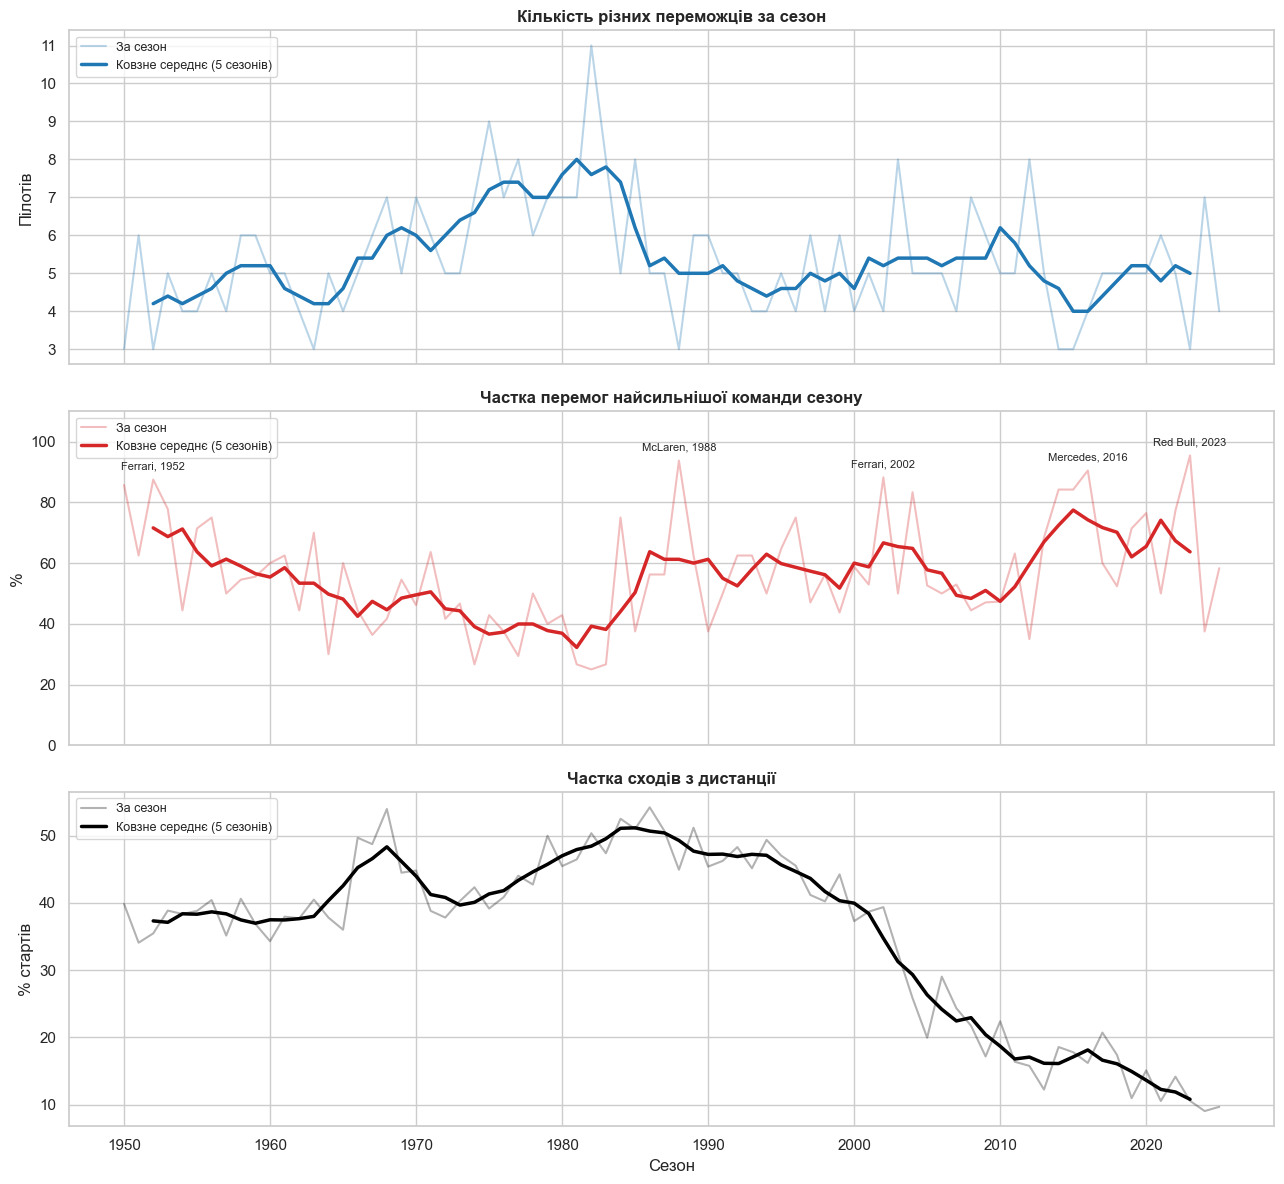

In [39]:
smooth = season[["different_winners", "top_team_win_share", "dnf_rate"]].rolling(
    5, center=True).mean()

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
panels = [
    ("different_winners", 1, "Кількість різних переможців за сезон", "Пілотів", "tab:blue"),
    ("top_team_win_share", 100, "Частка перемог найсильнішої команди сезону", "%", "tab:red"),
    ("dnf_rate", 100, "Частка сходів з дистанції", "% стартів", "black"),
]
for ax, (col, k, title, ylabel, color) in zip(axes, panels):
    ax.plot(season.index, season[col] * k, color=color, alpha=0.3, label="За сезон")
    ax.plot(smooth.index, smooth[col] * k, color=color, linewidth=2.5,
            label="Ковзне середнє (5 сезонів)")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper left", fontsize=9)

axes[1].set_ylim(0, 110)
for year in [1952, 1988, 2002, 2016, 2023]:
    axes[1].annotate(f"{season.loc[year, 'top_team']}, {year}",
                     (year, season.loc[year, "top_team_win_share"] * 100),
                     xytext=(0, 7), textcoords="offset points", ha="center",
                     fontsize=8)
axes[2].set_xlabel("Сезон")

plt.tight_layout()
save_fig(fig, "01_competitiveness_and_dnf.png")
plt.show()

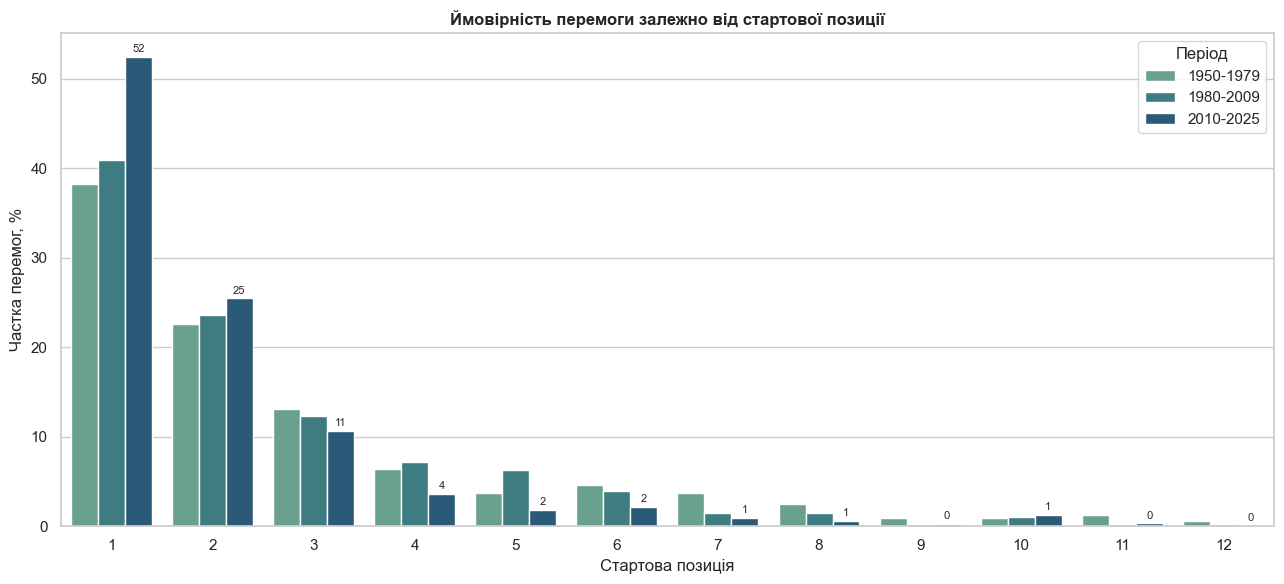

In [40]:
era = np.where(known_grid["year"] < 1980, "1950-1979",
               np.where(known_grid["year"] < 2010, "1980-2009", "2010-2025"))
grid_era = (known_grid.assign(era=era)
            .query("gridPositionNumber <= 12")
            .groupby(["era", "gridPositionNumber"])["win"].mean()
            .mul(100).reset_index())

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=grid_era, x="gridPositionNumber", y="win", hue="era",
            palette="crest", ax=ax)
ax.set_title("Ймовірність перемоги залежно від стартової позиції")
ax.set_xlabel("Стартова позиція")
ax.set_ylabel("Частка перемог, %")
ax.legend(title="Період")
for container in ax.containers[-1:]:
    ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
plt.tight_layout()
save_fig(fig, "02_win_probability_by_grid.png")
plt.show()

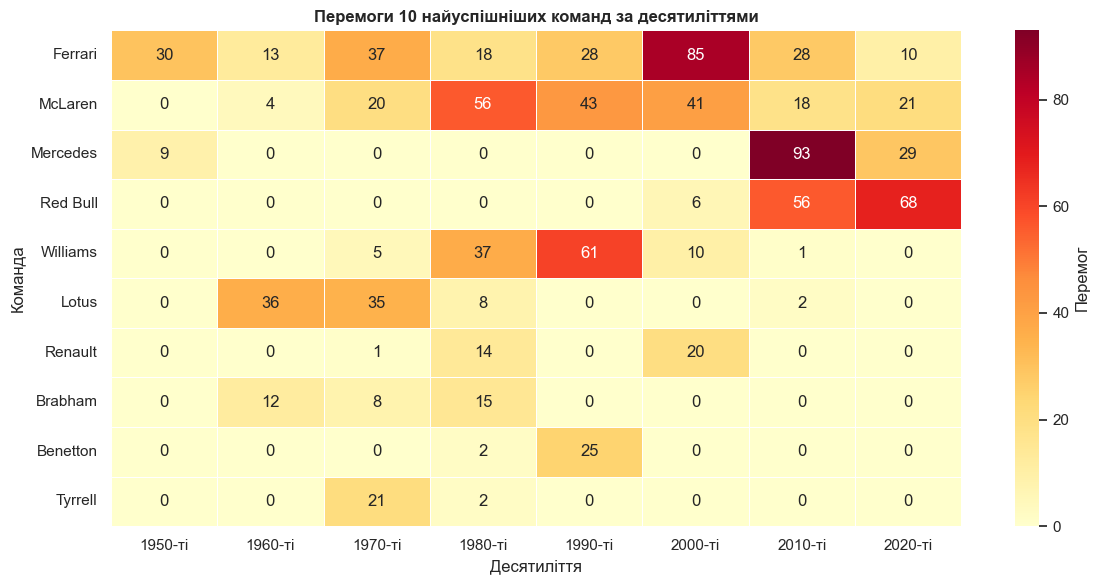

In [41]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(wins_by_decade, annot=True, fmt="d", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"label": "Перемог"}, ax=ax)
ax.set_title("Перемоги 10 найуспішніших команд за десятиліттями")
ax.set_xlabel("Десятиліття")
ax.set_ylabel("Команда")
plt.tight_layout()
save_fig(fig, "03_team_wins_heatmap.png")
plt.show()

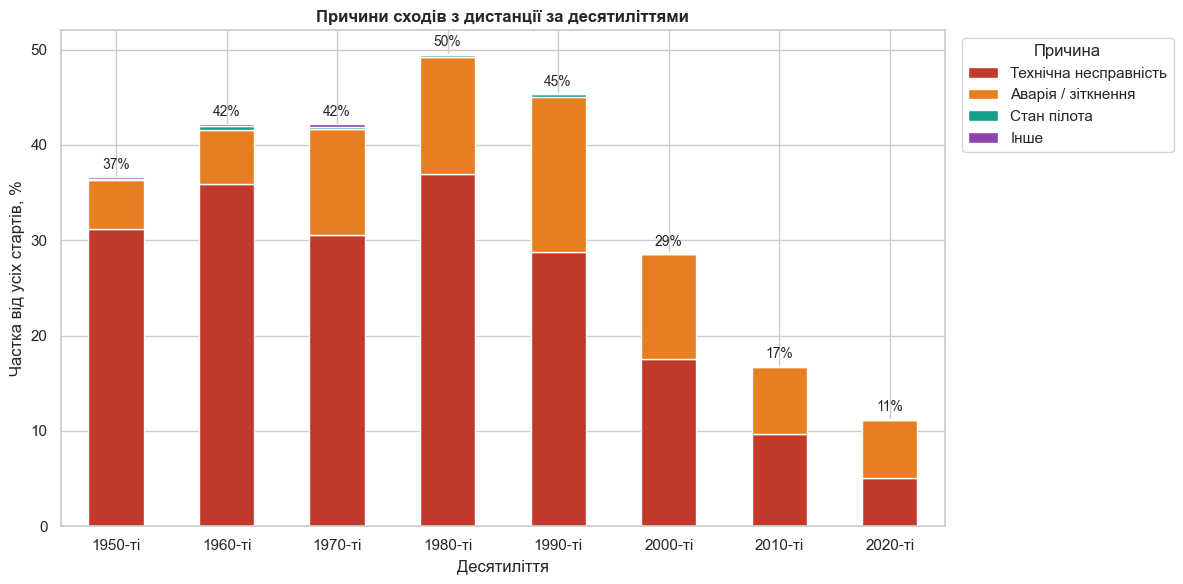

In [42]:
causes = dnf_share.drop(columns="Без сходу").sum().sort_values(ascending=False).index
dnf_plot = dnf_share[causes] * 100

fig, ax = plt.subplots(figsize=(12, 6))
dnf_plot.plot(kind="bar", stacked=True, ax=ax,
              color=["#c0392b", "#e67e22", "#16a085", "#8e44ad", "#95a5a6"][:len(causes)])
ax.set_title("Причини сходів з дистанції за десятиліттями")
ax.set_xlabel("Десятиліття")
ax.set_ylabel("Частка від усіх стартів, %")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Причина", bbox_to_anchor=(1.01, 1), loc="upper left")
for i, total in enumerate(dnf_plot.sum(axis=1)):
    ax.text(i, total + 0.8, f"{total:.0f}%", ha="center", fontsize=10)
plt.tight_layout()
save_fig(fig, "04_dnf_causes_by_decade.png")
plt.show()

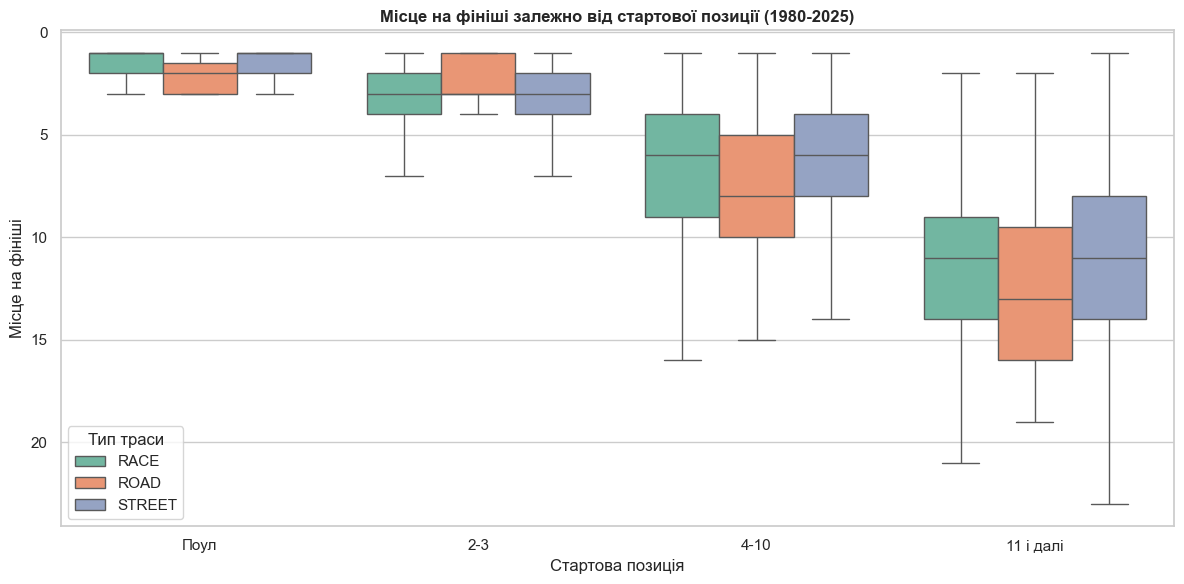

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=finished.query("year >= 1980"), x="grid_group", y="positionNumber",
            hue="circuitType", hue_order=["RACE", "ROAD", "STREET"],
            palette="Set2", showfliers=False, ax=ax)
ax.invert_yaxis()
ax.set_title("Місце на фініші залежно від стартової позиції (1980-2025)")
ax.set_xlabel("Стартова позиція")
ax.set_ylabel("Місце на фініші")
ax.legend(title="Тип траси")
plt.tight_layout()
save_fig(fig, "05_finish_by_grid_boxplot.png")
plt.show()

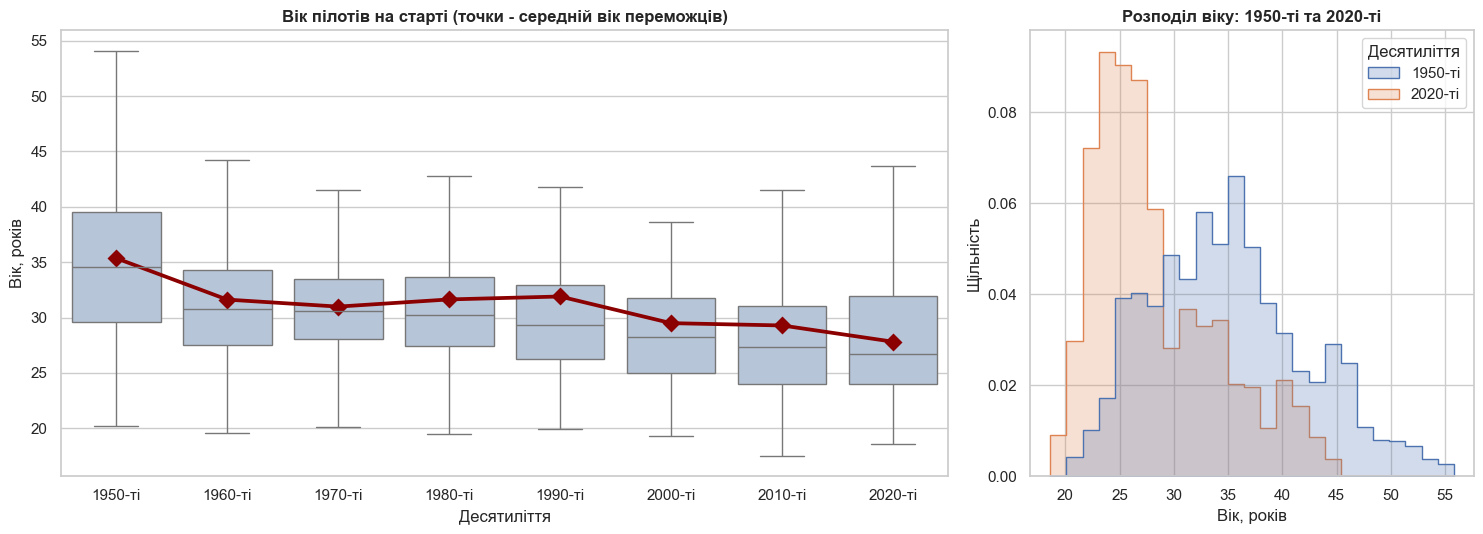

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2, 1]})

sns.boxplot(data=df, x="decade", y="driver_age", color="lightsteelblue",
            showfliers=False, ax=axes[0])
sns.pointplot(data=df[df["win"]], x="decade", y="driver_age", estimator="mean",
              errorbar=None, color="darkred", markers="D", ax=axes[0])
axes[0].set_title("Вік пілотів на старті (точки - середній вік переможців)")
axes[0].set_xlabel("Десятиліття")
axes[0].set_ylabel("Вік, років")

sns.histplot(data=df[df["decade"].isin(["1950-ті", "2020-ті"])], x="driver_age",
             hue="decade", stat="density", common_norm=False, bins=25,
             element="step", ax=axes[1])
axes[1].set_title("Розподіл віку: 1950-ті та 2020-ті")
axes[1].get_legend().set_title("Десятиліття")
axes[1].set_xlabel("Вік, років")
axes[1].set_ylabel("Щільність")

plt.tight_layout()
save_fig(fig, "06_driver_age.png")
plt.show()

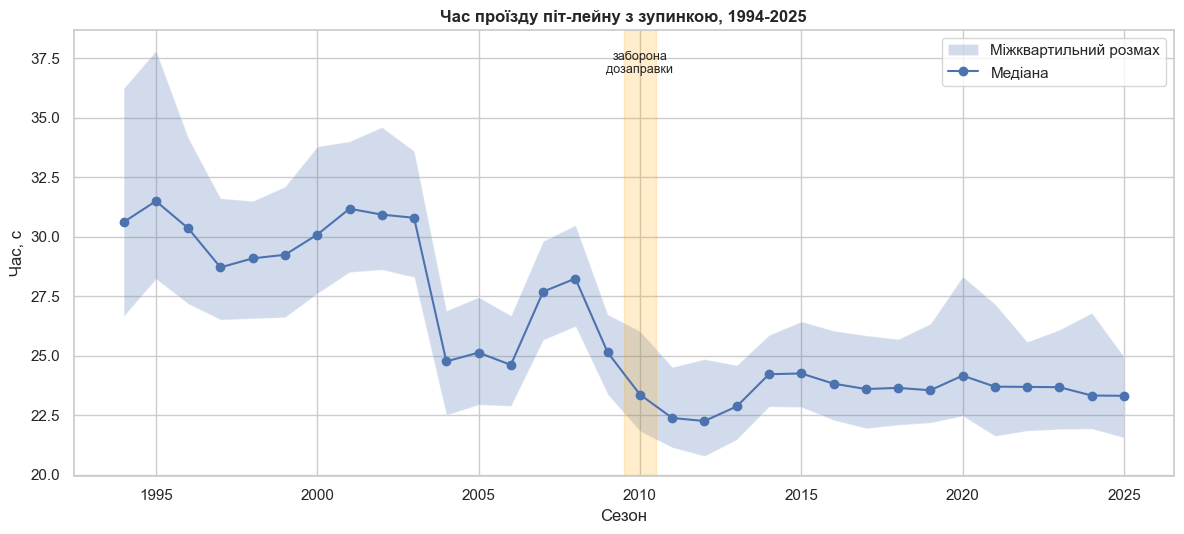

In [45]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.fill_between(pit_by_year.index, pit_by_year["q1"], pit_by_year["q3"],
                alpha=0.25, label="Міжквартильний розмах")
ax.plot(pit_by_year.index, pit_by_year["median"], marker="o", label="Медіана")
ax.axvspan(2009.5, 2010.5, color="orange", alpha=0.2)
ax.text(2010, pit_by_year["q3"].max(), "заборона\nдозаправки", ha="center",
        va="top", fontsize=9)
ax.set_title("Час проїзду піт-лейну з зупинкою, 1994-2025")
ax.set_xlabel("Сезон")
ax.set_ylabel("Час, с")
ax.legend()
plt.tight_layout()
save_fig(fig, "07_pit_stop_time.png")
plt.show()

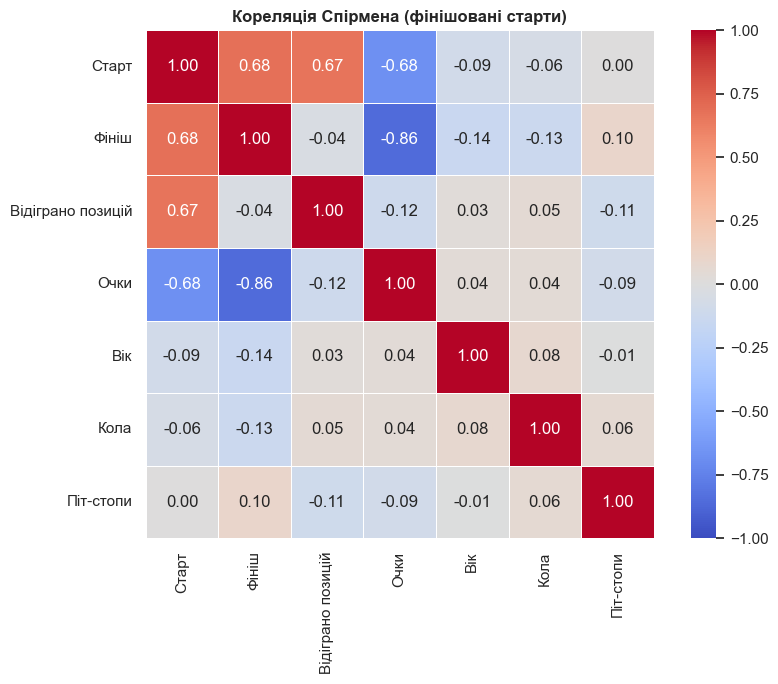

In [46]:
labels = ["Старт", "Фініш", "Відіграно позицій", "Очки", "Вік", "Кола", "Піт-стопи"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Кореляція Спірмена (фінішовані старти)")
plt.tight_layout()
save_fig(fig, "08_correlation_heatmap.png")
plt.show()

## 7. Збереження результатів для Tableau

In [47]:
starts_clean = df[[
    "raceId", "year", "decade", "round", "date", "grandPrix", "circuit",
    "circuitType", "circuitCountry", "latitude", "longitude", "driver",
    "nationality", "constructor", "gridPositionNumber", "positionNumber",
    "status", "dnf_cause", "reasonRetired", "points", "win", "podium",
    "positions_gained", "driver_age", "age_group", "home_race", "grid_group",
]].sort_values(["date", "positionNumber"])

starts_clean.to_csv(PROCESSED / "f1_starts_clean.csv", index=False)

# для Tableau - зрозумілі назви полів і прапорці 0/1, щоб їх можна було усереднювати
tableau_starts = starts_clean.assign(
    dnf=starts_clean["status"].eq("Схід").astype(int),
    win=starts_clean["win"].astype(int),
    podium=starts_clean["podium"].astype(int),
    home_race=starts_clean["home_race"].astype(int),
).rename(columns={
    "raceId": "Race Id", "year": "Year", "decade": "Decade", "round": "Round",
    "date": "Date", "grandPrix": "Grand Prix", "circuit": "Circuit",
    "circuitType": "Circuit Type", "circuitCountry": "Circuit Country",
    "latitude": "Latitude", "longitude": "Longitude", "driver": "Driver",
    "nationality": "Nationality", "constructor": "Constructor",
    "gridPositionNumber": "Grid", "positionNumber": "Finish", "status": "Status",
    "dnf_cause": "DNF Cause", "reasonRetired": "Retirement Reason",
    "points": "Points", "win": "Win", "podium": "Podium", "dnf": "DNF",
    "positions_gained": "Positions Gained", "driver_age": "Driver Age",
    "age_group": "Age Group", "home_race": "Home Race", "grid_group": "Grid Group",
})
tableau_starts.to_csv(TABLEAU / "f1_starts.csv", index=False, encoding="utf-8")
season.reset_index().to_csv(TABLEAU / "f1_seasons.csv", index=False)
pit_full[["year", "raceId", "constructor", "driverId", "stop", "lap", "seconds"]] \
    .to_csv(TABLEAU / "f1_pit_stops.csv", index=False)

experienced.reset_index().to_csv(EXPORTS / "drivers_ranking.csv", index=False)
team_stats.reset_index().to_csv(EXPORTS / "constructors_ranking.csv", index=False)
wins_by_decade.to_csv(EXPORTS / "wins_by_decade.csv")
dnf_share.to_csv(EXPORTS / "dnf_share_by_decade.csv")

check = pd.read_csv(PROCESSED / "f1_starts_clean.csv")
print("Записано:", starts_clean.shape, " прочитано:", check.shape)
sorted(p.name for p in TABLEAU.glob("*.csv"))

Записано: (25518, 27)  прочитано: (25518, 27)


['f1_pit_stops.csv', 'f1_seasons.csv', 'f1_starts.csv']

## 8. Висновки

1. **Конкурентність.** У сезоні в середньому 4–7 різних переможців. Найбільш відкритими були кінець 1970-х і початок 1980-х (1982 – 11 переможців). У 2010-х і 2020-х найсильніша команда в середньому вигравала 66 % гонок; рекорд – Red Bull у 2023 році (21 з 22, 95.5 %).
2. **Стартова позиція.** З поулу виграно 43.4 % гонок, у 2010–2025 – уже 52 %. З 10-го місця і далі – лише 3.5 % перемог. Кореляція Спірмена між стартом і фінішем зросла з 0.64 у 1950-х до 0.74–0.78 після 2000 року. Для вуличних трас поул дає перемогу трохи частіше (45.8 % проти 43.1 %), але різниця невелика.
3. **Надійність.** Частка сходів впала з 49 % стартів у 1980-х до 11 % у 2020-х. Технічних сходів стало в 7 разів менше (36.9 → 5.0 на 100 стартів), але двигун досі найчастіша технічна причина.
4. **Лідери.** Найбільше перемог – у Hamilton (105), Schumacher (91), Verstappen (71); за часткою перемог серед пілотів з 50+ стартами першим є Fangio (41 %). Серед команд за кількістю перемог лідирує Ferrari (249), за часткою – Mercedes (38 % гонок). Лідери змінювались по десятиліттях: Lotus → McLaren/Williams → Ferrari → Mercedes → Red Bull.
5. **Вік і домашні гонки.** Середній вік пілотів зменшився з 35 до 28 років, переможців – з 35.4 до 27.8. Переваги домашньої гонки дані не показують: вдома пілоти в середньому фінішують на 0.5 позиції гірше.
6. **Піт-стопи.** Медіанний час проїзду піт-лейну скоротився з 30.6 с (1994) до 23.3 с (2025); після заборони дозаправки у 2010 році він стабільно тримається в межах 22–24 с, а різниця між командами у 2025 році менша за 1 с.

**Обмеження:** очки та кількість гонок у сезоні змінювались за регламентом, тому порівнюються частки, а не абсолютні очки; час піт-стопу в даних – це весь проїзд піт-лейну, а не лише робота механіків; результати описують зв'язки, а не причини.